# Taller 2. Predicción de abandono (churn) de clientes
## Notebook 1 de 3. Entendimiento y preparación de los datos

**MINE-4101 Ciencia de Datos Aplicada, Universidad de los Andes, 2026-20**

**Integrantes:**
* Lina Muñoz (202310172)
* Yair Andrade (202310241)

**Contexto.** FinAlpes, una fintech colombiana, quiere una prueba de concepto de una herramienta que identifique a tiempo a los clientes con riesgo de abandonar su banco, para dirigirles campañas de retención. Para eso cuenta con una muestra de clientes europeos.

**Orden de ejecución**
1. `01_entendimiento_preparacion.ipynb` (este notebook), con el punto 1. Al final genera el archivo `data/churn_limpio.csv`.
2. `02_modelado_evaluacion.ipynb`, con los puntos 2, 3 y 4. Parte de `data/churn_limpio.csv`, por lo que este notebook debe ejecutarse primero.
3. `03_generacion_valor.ipynb`, con el punto 5. También parte de `data/churn_limpio.csv`.

**Alcance de la limpieza en este notebook.** Aquí solo se aplican correcciones que no dependen de estadísticas calculadas sobre los datos como eliminar duplicados, unificar categorías, marcar valores imposibles como faltantes.

**Contenido**
* 0. Configuración del entorno
* 1. Entendimiento y preparación de los datos

## 0. Configuración del entorno

En esta celda importamos las librerías que usaremos durante todo el notebook y fijamos algunas opciones generales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

## 1. Entendimiento y preparación de los datos

El objetivo de esta sección es conocer el dataset antes de modelar, es decir, qué contiene, de qué tipo es cada variable, qué tan limpio está y cómo se distribuye la variable objetivo.

### 1.1 Carga de los datos

In [2]:
df_raw = pd.read_csv("data/churn.csv")
df_raw.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.00,France,Female,46.00,9,0.00,1,1,1,81014.50,1
1,689.00,Germany,Male,67.00,9,157094.78,1,1,1,99490.01,0
2,477.00,Spain,Female,48.00,2,129120.64,1,0,1,26475.79,0
3,573.00,Germany,Female,35.00,9,206868.78,2,0,1,102986.15,0
4,849.00,France,Male,69.00,7,71996.09,1,1,1,139065.94,0


### 1.2 Dimensiones del dataset

Revisamos cuántos registros (filas) y cuántas variables (columnas) tenemos. Cada fila debería representar un cliente, por lo que el número de filas nos da una primera idea del tamaño de la muestra.

In [3]:
n_filas, n_columnas = df_raw.shape
print(f"Número de registros: {n_filas}")
print(f"Número de variables: {n_columnas}")

Número de registros: 10045
Número de variables: 11


### 1.3 Tipos de variables

Revisamos el tipo de dato con el que pandas leyó cada columna y cuántos valores distintos tiene.

In [4]:
resumen_tipos = pd.DataFrame({
    "tipo_pandas": df_raw.dtypes,
    "valores_unicos": df_raw.nunique(),
    "ejemplo": df_raw.iloc[0],
})
resumen_tipos

,tipo_pandas,valores_unicos,ejemplo
credit_score,float64,461,418.00
country,object,9,France
gender,object,4,Female
age,float64,76,46.00
tenure,int64,14,9
balance,float64,6240,0.00
products_number,int64,4,1
credit_card,int64,2,1
active_member,int64,2,1
estimated_salary,float64,9649,81014.50


A partir de la tabla anterior clasificamos las variables así:

| Variable | Tipo | Descripción |
|---|---|---|
| `credit_score` | Numérica discreta | Puntaje crediticio del cliente |
| `country` | Categórica nominal | País del cliente |
| `gender` | Categórica nominal | Género del cliente |
| `age` | Numérica discreta | Edad en años |
| `tenure` | Numérica discreta | Años de antigüedad como cliente del banco |
| `balance` | Numérica continua | Saldo en la cuenta |
| `products_number` | Numérica discreta (ordinal) | Número de productos que tiene con el banco |
| `credit_card` | Binaria | 1 si tiene tarjeta de crédito |
| `active_member` | Binaria | 1 si es un cliente activo |
| `estimated_salary` | Numérica continua | Salario estimado |
| `churn` | Binaria (**variable objetivo**) | 1 si el cliente abandonó el banco |

### 1.4 Diagnóstico de calidad de los datos

Antes de corregir, hacemos un diagnóstico completo de problemas de calidad.

Revisamos cuatro tipos de problemas:
1. Valores faltantes
2. Registros duplicados
3. Inconsistencias en variables categóricas
4. Valores fuera de un rango posible

#### 1.4.1 Valores faltantes

Contamos cuántos valores vacíos (`NaN`) tiene cada variable y qué porcentaje del total representan.

In [5]:
faltantes = pd.DataFrame({
    "faltantes": df_raw.isna().sum(),
    "porcentaje": df_raw.isna().mean() * 100,
})
faltantes[faltantes["faltantes"] > 0].sort_values("porcentaje", ascending=False)

,faltantes,porcentaje
estimated_salary,350,3.48
age,300,2.99
credit_score,250,2.49
balance,200,1.99


Cuatro variables tienen faltantes, `estimated_salary` (3,48%), `age` (2,99%), `credit_score` (2,49%) y `balance` (1,99%). Ninguna supera el 5%, por lo que no es necesario descartar variables.

Estos faltantes se imputarán en el notebook 2, después de separar entrenamiento y prueba.

#### 1.4.2 Registros duplicados

Buscamos filas idénticas en todas sus columnas. El dataset no tiene un identificador de cliente, así que no podemos confirmar directamente si dos filas son el mismo cliente. Sin embargo, variables como `balance` y `estimated_salary` tienen decimales, y es muy poco probable que dos clientes distintos coincidan exactamente en todas las variables.

In [6]:
n_duplicados = df_raw.duplicated().sum()
print(f"Filas duplicadas: {n_duplicados} ({n_duplicados / len(df_raw) * 100:.2f}% del total)")

df_raw[df_raw.duplicated(keep=False)].sort_values(list(df_raw.columns)).head(6)

Filas duplicadas: 45 (0.45% del total)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.00,France,Female,29.00,4,85646.81,1,0,0,63233.02,1
5672,497.00,France,Female,29.00,4,85646.81,1,0,0,63233.02,1
2390,499.00,Germany,Male,36.00,5,131142.53,2,1,0,174918.46,0
7450,499.00,Germany,Male,36.00,5,131142.53,2,1,0,174918.46,0
2784,528.00,France,Female,27.00,7,176227.07,2,0,1,139481.53,0
6920,528.00,France,Female,27.00,7,176227.07,2,0,1,139481.53,0


#### 1.4.3 Consistencia de variables categóricas

Revisamos los valores distintos de `country` y `gender`. Buscamos categorías que representen lo mismo pero estén escritas de forma diferente (mayúsculas, abreviaturas).

In [7]:
for col in ["country", "gender"]:
    print(f"Valores de {col}:")
    print(df_raw[col].value_counts(), "\n")

Valores de country:
country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64 

Valores de gender:
gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64 



#### 1.4.4 Rangos de variables numéricas

Revisamos el mínimo y el máximo de cada variable numérica. El objetivo es detectar valores que no son posibles en la realidad, por ejemplo una edad negativa.

In [8]:
df_raw.describe().T[["min", "max"]]

,min,max
credit_score,95.00,1200.00
age,-1.00,210.00
tenure,-2.00,25.00
balance,0.00,250898.09
products_number,1.00,4.00
credit_card,0.00,1.00
active_member,0.00,1.00
estimated_salary,-5000.00,199992.48
churn,0.00,1.00


La tabla muestra problemas en cuatro variables, `age` (mínimo -1, máximo 210), `credit_score` (mínimo 95, máximo 1200), `tenure` (mínimo -2, máximo 25) y `estimated_salary` (mínimo -5000). Las analizamos una por una en la sección de limpieza.

### 1.5 Limpieza de los datos

A partir del análisis anterior, ahora sí corregimos los problemas y dejamos listos los datos.

In [9]:
df = df_raw.copy()

#### 1.5.1 Consistencia de variables categóricas

En el diagnóstico vimos que un mismo país aparece escrito de varias formas ("France", "FRANCE", "france") y que el género mezcla valores completos con abreviaturas ("Male" y "M"), por lo que es necesario corregir y dejar todo consistente.

In [10]:
for col in ["country", "gender"]:
    print(f"{col}: {[repr(v) for v in df[col].unique()]}")

country: ["'France'", "'Germany'", "'Spain'", "'GERMANY'", "'FRANCE'", "'SPAIN'", "'spain '", "'france '", "'germany '"]
gender: ["'Female'", "'Male'", "'F'", "'M'"]


Aplicamos dos correcciones:
* **`country`.** Eliminamos espacios con `str.strip()` y dejamos solo la primera letra en mayúscula con `str.capitalize()`. Así todas las variantes quedan como "France", "Germany" o "Spain".
* **`gender`.** Eliminamos espacios y reemplazamos las abreviaturas por el valor completo.

In [11]:
df["country"] = df["country"].str.strip().str.capitalize()

MAPA_GENERO = {"M": "Male", "F": "Female"}
df["gender"] = df["gender"].str.strip().replace(MAPA_GENERO)

for col in ["country", "gender"]:
    print(df[col].value_counts(), "\n")

country
France     5042
Germany    2517
Spain      2486
Name: count, dtype: int64 

gender
Male      5480
Female    4565
Name: count, dtype: int64 



Ahora cada variable tiene solo sus categorías válidas, tres países y dos géneros.

#### 1.5.2 Registros duplicados

Eliminamos las filas duplicadas y conservamos una sola copia de cada una. Esta corrección se hace **después** de unificar las categorías, porque dos filas iguales que solo se diferencian en "France" y "FRANCE" no se detectarían como duplicadas si se revisaran antes.

Eliminar duplicados es importante por dos razones:
* Un cliente repetido pesa el doble en el entrenamiento sin aportar información nueva.
* Si una copia queda en entrenamiento y la otra en prueba, el modelo sería evaluado con un cliente que ya vio. Eso es una forma de data leakage que inflaría las métricas.

In [12]:
filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
filas_despues = len(df)

print(f"Filas eliminadas: {filas_antes - filas_despues}")
print(f"Filas restantes: {filas_despues}")

Filas eliminadas: 45
Filas restantes: 10000


#### 1.5.3 Edades imposibles

Revisamos primero cuáles son las edades fuera de un rango posible. Definimos como válido el rango de **18 a 100 años**:
* **18** porque es la edad mínima de la población que representa el dataset. Fuera de tres valores aislados (-1, 0 y 5), no hay ningún cliente entre 1 y 17 años, y el siguiente valor es 18, con 22 clientes.
* **100** como límite superior amplio, que no excluye casos reales poco frecuentes. La edad válida más alta del dataset es 92.

In [13]:
EDAD_MIN = 18
EDAD_MAX = 100

edad_invalida = (df["age"] < EDAD_MIN) | (df["age"] > EDAD_MAX)
df.loc[edad_invalida, ["age", "tenure", "active_member", "churn"]]

,age,tenure,active_member,churn
991,130.00,5,1,0
1775,5.00,6,1,0
1818,0.00,9,1,0
4027,210.00,10,1,0
4526,150.00,2,0,0
7203,-1.00,7,1,1


Hay 6 edades imposibles, tres muy altas (130, 150 y 210) y tres muy bajas (-1, 0 y 5).

Consideramos que se trata de errores de captura y no de clientes reales. En los tres casos bajos, además, la edad es inconsistente con el resto del registro. El cliente de 5 años tendría 6 años de antigüedad (sería cliente desde antes de nacer), un puntaje crediticio de 702, que exige un historial de crédito, y una tarjeta de crédito. El de 0 años tendría 9 años de antigüedad.

**Decisión.** Reemplazamos estas edades por `NaN` en lugar de eliminar las filas. El error está en una sola celda y el resto de la información del cliente sigue siendo válida. Estos valores se imputarán en el notebook 2 junto con los demás faltantes de `age`.

In [14]:
faltantes_antes = df["age"].isna().sum()
df.loc[edad_invalida, "age"] = np.nan
faltantes_despues = df["age"].isna().sum()

print(f"Edades corregidas: {edad_invalida.sum()}")
print(f"Faltantes en age: {faltantes_antes} antes, {faltantes_despues} después")

Edades corregidas: 6
Faltantes en age: 300 antes, 306 después


#### 1.5.4 Puntajes crediticios imposibles

El dataset no indica en qué escala está `credit_score`, y las escalas cambian según la entidad que calcula el puntaje (la escala más usada, la de FICO, va de 300 a 850). Por eso, primero revisamos qué escala sugieren los propios datos. Mostramos los valores más bajos y más altos, y contamos cuántos clientes tienen exactamente 850.

In [15]:
valores_score = np.sort(df["credit_score"].dropna().unique())
print(f"Cinco valores más bajos: {valores_score[:5]}")
print(f"Cinco valores más altos: {valores_score[-5:]}")
print(f"Clientes con puntaje exactamente 850: {(df['credit_score'] == 850).sum()}")

Cinco valores más bajos: [ 95. 120. 350. 351. 358.]
Cinco valores más altos: [ 848.  849.  850.  999. 1200.]
Clientes con puntaje exactamente 850: 227


Fuera de cuatro valores aislados (95, 120, 999 y 1200), los puntajes van de 350 a 850. Además, más de 200 clientes tienen exactamente 850. Esa acumulación en 850 indica que ese es el límite superior del rango.

Definimos ese rango como válido. Usamos 300 y no 350 como mínimo porque 300 es el límite de la escala. Si usáramos 350 estaríamos ajustando el rango a esta muestra en particular, y no habría cómo justificarlo para clientes nuevos.

In [16]:
SCORE_MIN = 300
SCORE_MAX = 850

score_invalido = (df["credit_score"] < SCORE_MIN) | (df["credit_score"] > SCORE_MAX)
df.loc[score_invalido, ["credit_score", "age", "balance", "churn"]]

,credit_score,age,balance,churn
1794,1200.00,39.00,0.00,0
1880,120.00,38.00,103653.51,0
6405,95.00,39.00,118336.14,0
9007,999.00,37.00,0.00,0


Hay 4 puntajes imposibles. Los valores 95, 120, 999 y 1200 están fuera de la escala. 

**Decisión.** Igual que con la edad, reemplazamos estos valores por `NaN` y conservamos el resto de la información del cliente. Se imputarán en el notebook 2.

In [17]:
faltantes_antes = df["credit_score"].isna().sum()
df.loc[score_invalido, "credit_score"] = np.nan
faltantes_despues = df["credit_score"].isna().sum()

print(f"Puntajes corregidos: {score_invalido.sum()}")
print(f"Faltantes en credit_score: {faltantes_antes} antes, {faltantes_despues} después")

Puntajes corregidos: 4
Faltantes en credit_score: 250 antes, 254 después


#### 1.5.5 Antigüedad (tenure) imposible

`tenure` indica cuántos años lleva el cliente con el banco. Aplicamos dos reglas:
1. **No puede ser negativa.** Una antigüedad de -2 años no tiene sentido.
2. **No puede ser mayor que la edad.** Nadie puede ser cliente desde antes de nacer.

La segunda regla compara dos variables entre sí. Es una validación de **consistencia**, que detecta errores que una revisión de rangos variable por variable no encontraría. Por ejemplo, una edad de 20 y una antigüedad de 25 están cada una dentro de valores razonables por separado, pero juntas son imposibles.


In [18]:
tenure_invalido = (df["tenure"] < 0) | (df["tenure"] > df["age"])
df.loc[tenure_invalido, ["age", "tenure", "churn"]]

,age,tenure,churn
5757,20.00,25,0
6287,36.00,-2,0


Hay 2 registros con antigüedad imposible, uno negativo y otro de un cliente de 20 años con 25 años de antigüedad.

Cuando la edad es `NaN`, la comparación `tenure > age` da `False`, por lo que esos registros no se marcan. Esto es correcto, porque sin edad no hay forma de verificar la consistencia.

**Decisión.** Reemplazamos la antigüedad de estos 2 registros por `NaN`.

In [19]:
faltantes_antes = df["tenure"].isna().sum()
df.loc[tenure_invalido, "tenure"] = np.nan
faltantes_despues = df["tenure"].isna().sum()

print(f"Antigüedades corregidas: {tenure_invalido.sum()}")
print(f"Faltantes en tenure: {faltantes_antes} antes, {faltantes_despues} después")

Antigüedades corregidas: 2
Faltantes en tenure: 0 antes, 2 después


#### 1.5.6 Salario estimado

En el diagnóstico encontramos salarios negativos, que son imposibles. También aparecen salarios positivos muy bajos (por ejemplo 11,58), que parecen poco realistas. Para decidir si estos últimos son atípicos, revisamos la distribución de la variable con un histograma y calculamos los límites del método del rango intercuartílico (IQR), que es un criterio estándar para identificar valores atípicos.

Límite inferior IQR: -96,525
Límite superior IQR: 296,908
Salarios negativos: 3
Salarios entre 0 y 1.000: 58


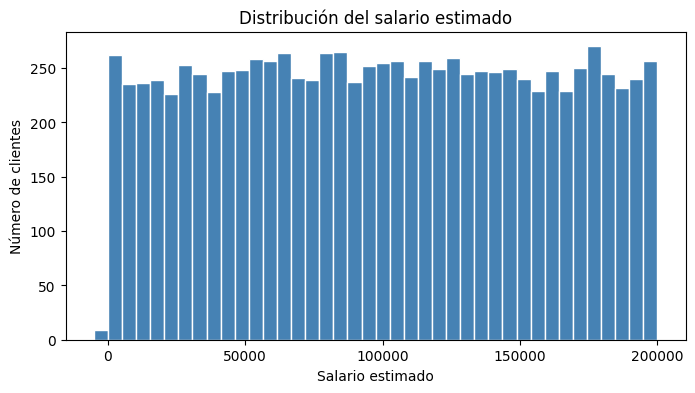

In [20]:
salario = df["estimated_salary"]

q1, q3 = salario.quantile([0.25, 0.75])
iqr = q3 - q1
print(f"Límite inferior IQR: {q1 - 1.5 * iqr:,.0f}")
print(f"Límite superior IQR: {q3 + 1.5 * iqr:,.0f}")
print(f"Salarios negativos: {(salario < 0).sum()}")
print(f"Salarios entre 0 y 1.000: {salario.between(0, 1000).sum()}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(salario.dropna(), bins=40, color="steelblue", edgecolor="white")
ax.set_title("Distribución del salario estimado")
ax.set_xlabel("Salario estimado")
ax.set_ylabel("Número de clientes")
plt.show()

La distribución del salario es casi uniforme entre 0 y 200.000. Hay más o menos la misma cantidad de clientes en cada rango de salario. Por eso el método IQR no marca ningún valor positivo como atípico. Así que un salario de 11,58 corresponde al extremo de la distribución y no a un valor atípico.

No tenemos un criterio de negocio que permita fijar un salario mínimo creíble (por ejemplo, no sabemos si el salario es anual o mensual, ni cómo se estimó). Eliminar esos valores sería una decisión arbitraria.

**Decisión.** Solo los salarios negativos se reemplazan por `NaN`. Los salarios positivos bajos se conservan.


In [21]:
salario_invalido = df["estimated_salary"] < 0

faltantes_antes = df["estimated_salary"].isna().sum()
df.loc[salario_invalido, "estimated_salary"] = np.nan
faltantes_despues = df["estimated_salary"].isna().sum()

print(f"Salarios corregidos: {salario_invalido.sum()}")
print(f"Faltantes en estimated_salary: {faltantes_antes} antes, {faltantes_despues} después")

Salarios corregidos: 3
Faltantes en estimated_salary: 350 antes, 353 después


### 1.6 Distribución de la variable objetivo

Antes de analizar las demás variables, revisamos cómo se distribuye `churn`. Esta es la pregunta más importante del entendimiento de datos para un problema de clasificación, que es **¿qué proporción de clientes abandonó el banco?** La respuesta define cómo debemos separar los datos, qué métricas tienen sentido y qué tan difícil será el problema para el modelo.


                 clientes  porcentaje
No abandonó (0)      7963       79.63
Abandonó (1)         2037       20.37


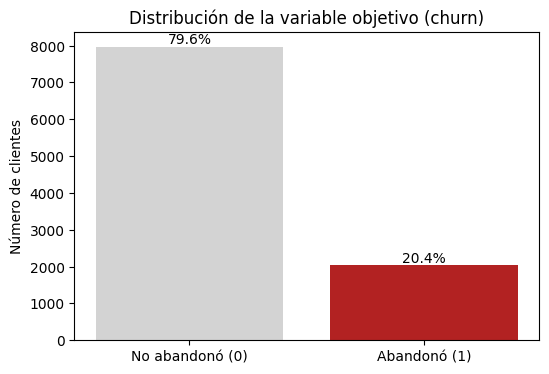

In [22]:
conteo_churn = df["churn"].value_counts().sort_index()
porcentaje_churn = df["churn"].value_counts(normalize=True).sort_index() * 100

tabla_churn = pd.DataFrame({
    "clientes": conteo_churn,
    "porcentaje": porcentaje_churn,
})
tabla_churn.index = ["No abandonó (0)", "Abandonó (1)"]
print(tabla_churn)

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(tabla_churn.index, tabla_churn["clientes"], color=["lightgray", "firebrick"])
for barra, pct in zip(barras, tabla_churn["porcentaje"]):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f"{pct:.1f}%",
            ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (churn)")
ax.set_ylabel("Número de clientes")
plt.show()

Aproximadamente **el 20% de los clientes abandonó el banco** y el 80% se quedó. Lo que significa:

1. **Las clases están desbalanceadas.** No es un desbalance extremo, pero sí es suficiente para que el modelo tienda a favorecer la clase mayoritaria.

2. **El accuracy es engañoso.** Un modelo que diga siempre "este cliente no se va" acertaría el 80% de las veces sin detectar a un solo cliente en riesgo. Ese 80% es la línea base que cualquier modelo debe superar, y por eso en el punto 3 nos enfocaremos en métricas como recall, precision, F1 y PR-AUC.

3. **La partición debe ser estratificada.** Al separar entrenamiento y prueba en el notebook 2, usaremos `stratify` para que ambos conjuntos conserven la misma proporción de 80/20. Si no, por azar un conjunto podría quedar con más clientes que abandonan que el otro.

4. **La muestra puede no representar al banco colombiano.** El enunciado indica que la tasa de deserción promedio en entidades financieras minoristas es cercana al 15%, mientras que en esta muestra europea es del 20%. Esta diferencia afecta cuántos de los clientes que el modelo señale realmente abandonarían, y por lo tanto el valor económico que se calcule en el punto 5.

### 1.7 Distribución de las variables explicativas

En esta sección hacemos el **EDA univariado**: revisamos cada variable por separado para entender cómo se distribuye.

| Grupo | Variables | Gráfico |
|---|---|---|
| Continuas | `age`, `credit_score`, `balance`, `estimated_salary` | Histograma y diagrama de caja |
| Discretas con pocos valores | `tenure`, `products_number` | Barras |
| Categóricas y binarias | `country`, `gender`, `credit_card`, `active_member` | Barras |


#### 1.7.1 Variables continuas

Primero calculamos medidas numéricas, como la media y la mediana (tendencia central), la desviación estándar y el IQR (dispersión) y la asimetría (forma). Comparar la media con la mediana es útil, porque cuando son muy diferentes indica que la distribución está sesgada o tiene valores extremos.

Para la asimetría (`skew`) un valor cercano a 0 indica una distribución simétrica, un valor positivo indica una cola larga hacia la derecha y uno negativo, una cola larga hacia la izquierda.

In [23]:
continuas = ["age", "credit_score", "balance", "estimated_salary"]

resumen_continuas = pd.DataFrame({
    "media": df[continuas].mean(),
    "mediana": df[continuas].median(),
    "desv_estandar": df[continuas].std(),
    "IQR": df[continuas].quantile(0.75) - df[continuas].quantile(0.25),
    "asimetria": df[continuas].skew(),
})
resumen_continuas

,media,mediana,desv_estandar,IQR,asimetria
age,38.92,37.00,10.47,12.00,1.00
credit_score,650.62,652.00,96.62,134.00,-0.07
balance,76286.25,97038.69,62413.45,127537.15,-0.14
estimated_salary,100069.67,100137.70,57484.03,98269.95,0.00


Ahora graficamos cada variable con dos gráficos complementarios:
* Un **histograma**, que muestra la forma de la distribución.
* Un **diagrama de caja**, que resume la mediana y el rango intercuartílico, y marca los valores atípicos.


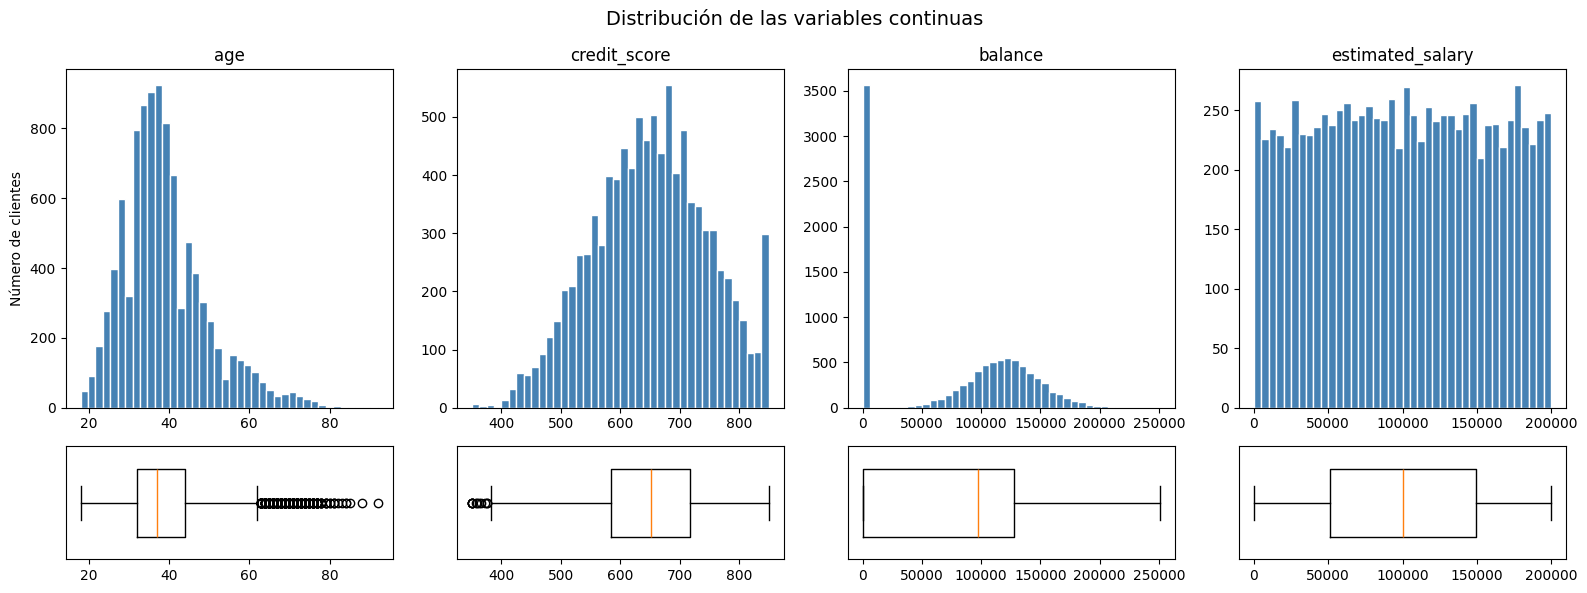

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), gridspec_kw={"height_ratios": [3, 1]})

for i, col in enumerate(continuas):
    datos = df[col].dropna()

    axes[0, i].hist(datos, bins=40, color="steelblue", edgecolor="white")
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel("Número de clientes" if i == 0 else "")

    axes[1, i].boxplot(datos, vert=False, widths=0.6)
    axes[1, i].set_yticks([])

fig.suptitle("Distribución de las variables continuas", fontsize=14)
plt.tight_layout()
plt.show()

**`age`.** La distribución tiene asimetría positiva (cola hacia la derecha). La mayoría de los clientes tiene entre 30 y 45 años, con mediana de 37, y hay menos clientes a medida que aumenta la edad. El diagrama de caja marca como atípicos a los clientes mayores de 62 años, pero son personas reales y no errores. 

**`credit_score`.** La distribución es casi simétrica centrada alrededor de 650. En el extremo derecho se ve una barra alta en 850, que corresponde a la acumulación en el techo de la escala que identificamos en la limpieza. Los pocos atípicos del lado izquierdo están dentro de la escala válida, por lo que también se conservan.

**`balance`.** Poco menos del 40% tiene balance de 0, y el resto tiene saldos concentrados alrededor de 120.000. Es una distribución con dos grupos claramente separados. Por eso la media (unos 76.000) no describe a ningún cliente típico. Está entre los dos grupos. Esta variable podría representarse mejor en el modelo agregando un indicador de si el cliente tiene saldo o no.

**`estimated_salary`.** Como vimos en la limpieza, la distribución es aproximadamente uniforme entre 0 y 200.000, con media y mediana casi iguales y sin atípicos.

#### 1.7.2 Variables discretas con pocos valores

`tenure` y `products_number` son numéricas, pero solo toman unos pocos valores enteros. Por eso un gráfico de barras es más apropiado.

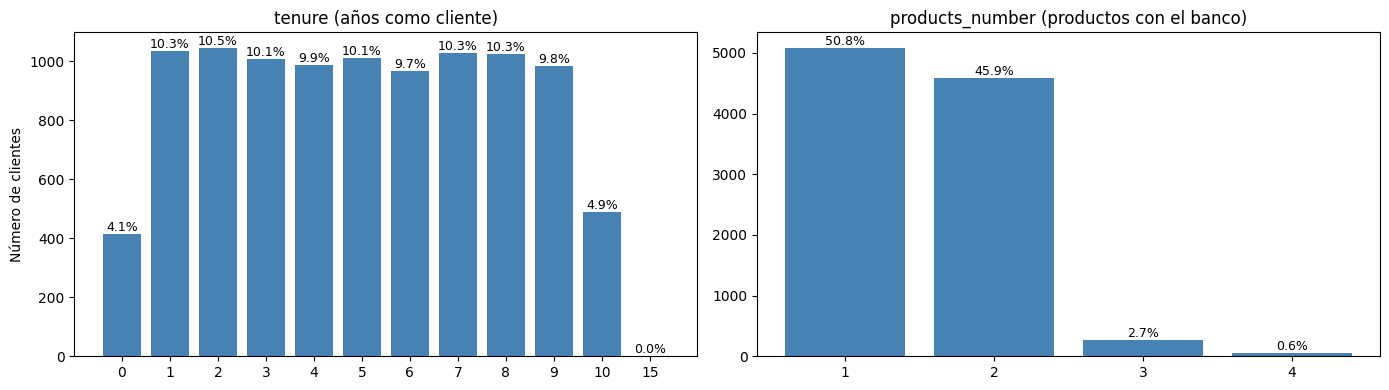

In [25]:
def graficar_barras(ax, serie, titulo, etiquetas=None):
    """Dibuja la frecuencia de cada valor de una variable con su porcentaje."""
    conteo = serie.dropna().value_counts().sort_index()
    porcentaje = conteo / conteo.sum() * 100

    nombres = [str(etiquetas.get(v, v)) if etiquetas else str(v) for v in conteo.index]
    barras = ax.bar(nombres, conteo.values, color="steelblue")

    for barra, pct in zip(barras, porcentaje):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(titulo)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
graficar_barras(axes[0], df["tenure"].astype("Int64"), "tenure (años como cliente)")
graficar_barras(axes[1], df["products_number"], "products_number (productos con el banco)")
axes[0].set_ylabel("Número de clientes")
plt.tight_layout()
plt.show()

**`tenure`.** Entre 1 y 9 años la distribución es prácticamente plana, con cerca del 10% de los clientes en cada valor. Los extremos 0 y 10 tienen aproximadamente la mitad (4% y 5%). 

**`products_number`.** Casi todos los clientes tienen 1 producto (51%) o 2 productos (46%). Los que tienen 3 o 4 son solo el 3% del total.

#### 1.7.3 Variables categóricas y binarias

Para las variables categóricas (`country`, `gender`) y binarias (`credit_card`, `active_member`) usamos barras con el porcentaje de cada categoría. En las binarias reemplazamos el 0 y el 1 por "No" y "Sí" por facilidad.


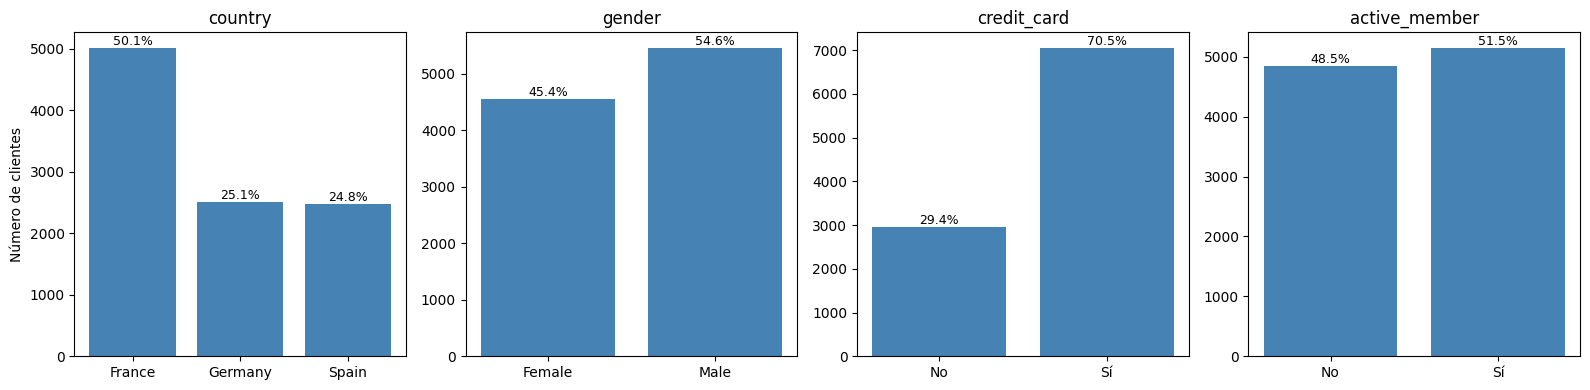

In [26]:
SI_NO = {0: "No", 1: "Sí"}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
graficar_barras(axes[0], df["country"], "country")
graficar_barras(axes[1], df["gender"], "gender")
graficar_barras(axes[2], df["credit_card"], "credit_card", etiquetas=SI_NO)
graficar_barras(axes[3], df["active_member"], "active_member", etiquetas=SI_NO)
axes[0].set_ylabel("Número de clientes")
plt.tight_layout()
plt.show()

**`country`.** La mitad de los clientes es de Francia (50%) y la otra mitad se reparte casi por igual entre Alemania y España (25% cada uno). Todos los clientes son europeos, lo que es una limitación importante. El modelo se aplicaría a un banco colombiano, cuyos clientes pueden comportarse de forma diferente.

**`gender`.** Hay un poco más de hombres (55%) que de mujeres (45%). La diferencia no es grande.

**`credit_card`.** El 71% de los clientes tiene tarjeta de crédito con el banco.

**`active_member`.** Los clientes se dividen casi en partes iguales entre activos (51%) e inactivos (49%). Que casi la mitad de los clientes esté inactiva es un dato relevante para el negocio, y en la siguiente sección revisaremos si los clientes inactivos abandonan el banco con mayor frecuencia.

### 1.8 Relación de las variables con el churn

En esta sección hacemos el **EDA bivariado**. Revisamos cómo se relaciona cada variable con el abandono.

Usamos dos herramientas complementarias:
1. Una **matriz de correlación** para las variables numéricas y binarias.
2. La **tasa de churn por grupo** para todas las variables, incluyendo las categóricas, donde la correlación no aplica.

#### 1.8.1 Matriz de correlación

Calculamos la correlación de **Spearman** entre las variables numéricas, las binarias y `churn`, y la mostramos como un mapa de calor. Usamos Spearman porque varias variables son discretas o binarias, y Spearman no exige que la relación sea lineal, solo que sea **monótona** (que cuando una variable sube, la otra tienda a subir, o a bajar).

La correlación va de -1 a 1. Valores cercanos a 0 indican que no hay relación monótona, valores positivos indican que ambas variables tienden a aumentar juntas y valores negativos, que una aumenta cuando la otra disminuye.

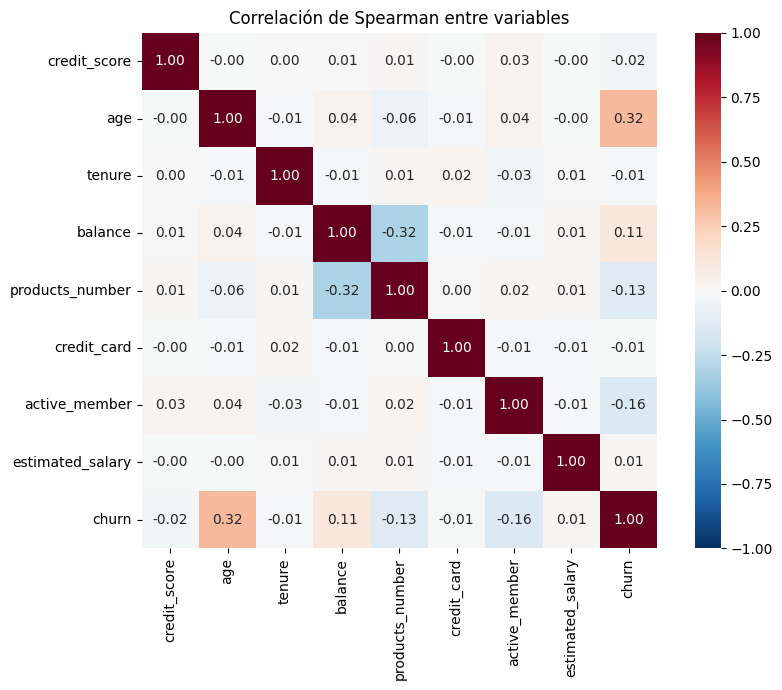

In [27]:
import seaborn as sns

variables_corr = ["credit_score", "age", "tenure", "balance", "products_number",
                  "credit_card", "active_member", "estimated_salary", "churn"]
matriz_corr = df[variables_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, ax=ax)
ax.set_title("Correlación de Spearman entre variables")
plt.tight_layout()
plt.show()

**Relación con `churn` (última fila).**
* **`age` (0,32)** es la variable con la relación más fuerte. Los clientes de mayor edad tienden a abandonar más.
* **`active_member` (-0,16).** Los clientes activos abandonan menos.
* **`products_number` (-0,12)** y **`balance` (0,11)** tienen relaciones débiles.
* `credit_score`, `tenure`, `credit_card` y `estimated_salary` tienen correlaciones prácticamente nulas. En el caso del salario, esto es consistente con la sospecha de la sección 1.5.6 de que es una variable estimada que aporta poca información.

**Relación entre variables explicativas.** La única relación relevante es entre `balance` y `products_number` (-0,32). Los clientes con saldo tienden a tener menos productos. El resto de las correlaciones son cercanas a 0, lo que indica que las variables no son redundantes entre sí.

#### 1.8.2 Tasa de churn por grupo

Para cada variable, dividimos a los clientes en grupos y calculamos qué porcentaje de cada grupo abandonó el banco.

Definimos la función `graficar_tasa_churn`, que dibuja la tasa de churn de cada grupo y agrega:
* Una **línea punteada con la tasa global** (20,4%), que sirve de referencia. Los grupos por encima de la línea abandonan más que el promedio.
* El **número de clientes de cada grupo** debajo de su nombre, porque una tasa calculada con pocos clientes es menos confiable.


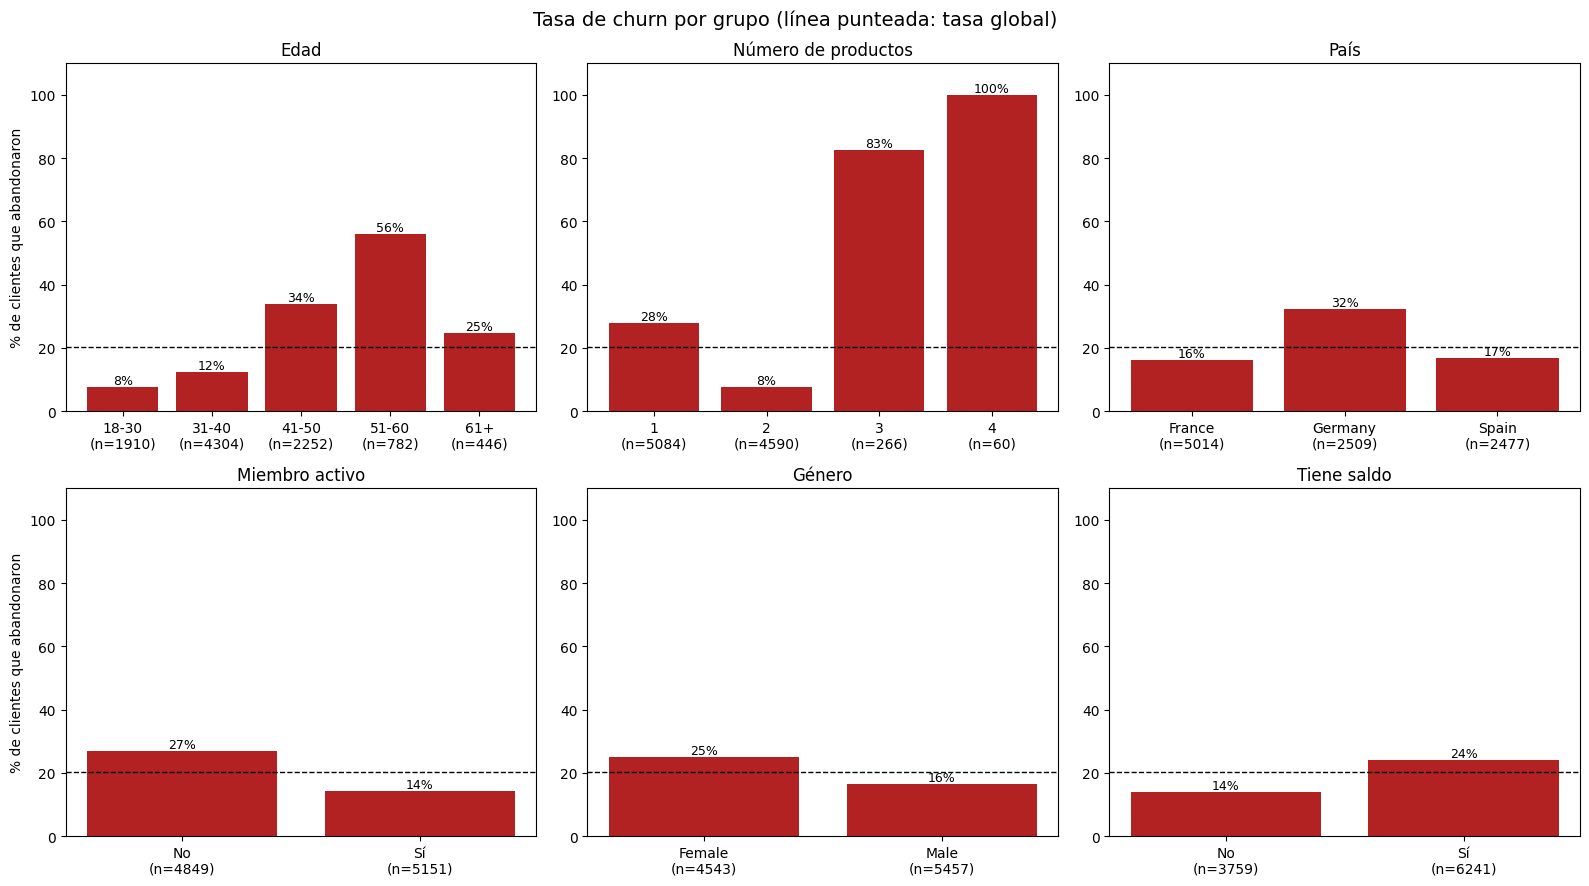

In [28]:
TASA_GLOBAL = df["churn"].mean() * 100


def graficar_tasa_churn(ax, grupos, titulo, etiquetas=None):
    """Dibuja el porcentaje de churn de cada grupo, con la tasa global como referencia."""
    resumen = df.groupby(grupos, observed=True)["churn"].agg(["mean", "size"])
    tasas = resumen["mean"] * 100

    nombres = [f"{etiquetas.get(g, g) if etiquetas else g}\n(n={n})"
               for g, n in zip(resumen.index, resumen["size"])]
    barras = ax.bar(nombres, tasas, color="firebrick")

    for barra, tasa in zip(barras, tasas):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{tasa:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.axhline(TASA_GLOBAL, color="black", linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_ylim(0, 110)


grupos_edad = pd.cut(df["age"], bins=[17, 30, 40, 50, 60, 100],
                     labels=["18-30", "31-40", "41-50", "51-60", "61+"])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
graficar_tasa_churn(axes[0, 0], grupos_edad, "Edad")
graficar_tasa_churn(axes[0, 1], df["products_number"], "Número de productos")
graficar_tasa_churn(axes[0, 2], df["country"], "País")
graficar_tasa_churn(axes[1, 0], df["active_member"], "Miembro activo", etiquetas=SI_NO)
graficar_tasa_churn(axes[1, 1], df["gender"], "Género")
graficar_tasa_churn(axes[1, 2], df["balance"] > 0, "Tiene saldo",
                    etiquetas={False: "No", True: "Sí"})
axes[0, 0].set_ylabel("% de clientes que abandonaron")
axes[1, 0].set_ylabel("% de clientes que abandonaron")
fig.suptitle("Tasa de churn por grupo (línea punteada: tasa global)", fontsize=14)
plt.tight_layout()
plt.show()

**El número de productos tiene la relación más fuerte, y la correlación no la detectó.** Los clientes con 2 productos abandonan muy poco (8%), los que tienen 1 abandonan más que el promedio (28%), y los que tienen 3 o 4 abandonan casi todos (83% y 100%). La relación no es monótona. El churn baja de 1 a 2 productos y luego sube bruscamente. Por eso la correlación de Spearman fue solo de -0,12. Eso sí los grupos de 3 y 4 productos tienen pocos clientes (266 y 60).

**La edad tampoco tiene una relación monótona.** El churn sube con la edad hasta el grupo de 51 a 60 años, donde abandona más de la mitad de los clientes (56%), y vuelve a bajar en los mayores de 60 (25%). La correlación de 0,32 capturaba solo la tendencia general.

**En el país, Alemania se destaca.** Los clientes alemanes abandonan el doble (32%) que los franceses y españoles (16% y 17%).

**Miembro activo.** Los clientes inactivos abandonan casi el doble (27%) que los activos (14%).

**Género.** Las mujeres abandonan más (25%) que los hombres (17%).

**Tiene saldo.** Los clientes con saldo abandonan más (24%) que los que tienen saldo 0 (14%).

#### 1.8.3 Alemania y el saldo

Los dos hallazgos anteriores sobre el país y el saldo podrían estar conectados. Revisamos qué porcentaje de clientes de cada país tiene saldo mayor a 0, usando una tabla cruzada.

In [29]:
tabla_pais_saldo = pd.crosstab(df["country"], df["balance"] > 0, normalize="index") * 100
tabla_pais_saldo.columns = ["Saldo = 0 (%)", "Saldo > 0 (%)"]
tabla_pais_saldo

,Saldo = 0 (%),Saldo > 0 (%)
country,,
France,49.42,50.58
Germany,2.11,97.89
Spain,49.58,50.42


En Francia y España la mitad de los clientes tiene saldo 0, pero en **Alemania casi el 100% tiene saldo**. Esto significa que parte de la relación entre tener saldo y abandonar podría deberse en realidad a que los clientes con saldo son, en buena medida, alemanes, y los alemanes abandonan más.

Para comprobarlo, repetimos la comparación del saldo excluyendo a Alemania.

In [30]:
sin_alemania = df[df["country"] != "Germany"]
churn_por_saldo = sin_alemania.groupby(sin_alemania["balance"] > 0)["churn"].mean() * 100
churn_por_saldo.index = ["Saldo = 0", "Saldo > 0"]
print("Tasa de churn sin clientes de Alemania (%):")
print(churn_por_saldo.round(1))

Tasa de churn sin clientes de Alemania (%):
Saldo = 0   13.90
Saldo > 0   18.70
Name: churn, dtype: float64


Sin Alemania, la diferencia se reduce. Los clientes con saldo abandonan 19% frente a 14% de los que no tienen saldo, en lugar de 24% frente a 14%. La relación sigue existiendo, pero es más pequeña.

### 1.9 Verificación y exportación de los datos limpios

Antes de guardar, verificamos que la limpieza quedó como esperábamos. Comparamos el dataset original con el limpio en tres aspectos, el número de filas, los valores faltantes por variable y las categorías de las variables de texto.

In [31]:
print(f"Filas: {len(df_raw)} en el original, {len(df)} en el limpio\n")

comparacion_faltantes = pd.DataFrame({
    "faltantes_original": df_raw.isna().sum(),
    "faltantes_limpio": df.isna().sum(),
})
print(comparacion_faltantes[comparacion_faltantes["faltantes_limpio"] > 0], "\n")

print(f"Países: {sorted(df['country'].unique())}")
print(f"Géneros: {sorted(df['gender'].unique())}")
print(f"Filas duplicadas restantes: {df.duplicated().sum()}")

Filas: 10045 en el original, 10000 en el limpio

                  faltantes_original  faltantes_limpio
credit_score                     250               254
age                              300               306
tenure                             0                 2
balance                          200               200
estimated_salary                 350               353 

Países: ['France', 'Germany', 'Spain']
Géneros: ['Female', 'Male']
Filas duplicadas restantes: 0


Guardamos el resultado en `data/churn_limpio.csv`. Este archivo es el punto de partida del notebook 2.

In [32]:
RUTA_LIMPIO = "data/churn_limpio.csv"
df.to_csv(RUTA_LIMPIO, index=False)
print(f"Archivo guardado en {RUTA_LIMPIO} con {df.shape[0]} filas y {df.shape[1]} columnas")

Archivo guardado en data/churn_limpio.csv con 10000 filas y 11 columnas


### 1.10 Resumen del entendimiento de los datos

**Dimensiones.** El dataset original tiene 10.045 registros y 11 variables, de las cuales 10 son explicativas y una es la variable objetivo `churn`. Después de la limpieza quedan 10.000 registros.

**Calidad de los datos y correcciones aplicadas**

| Problema | Variable | Registros | Tratamiento |
|---|---|---|---|
| Categorías escritas de varias formas | `country`, `gender` | 95 | Unificadas |
| Filas duplicadas | Todas | 45 | Eliminadas |
| Edad fuera de 18 a 100 | `age` | 6 | Convertidas a `NaN` |
| Puntaje fuera de 300 a 850 | `credit_score` | 4 | Convertidas a `NaN` |
| Antigüedad negativa o mayor que la edad | `tenure` | 2 | Convertidas a `NaN` |
| Salario negativo | `estimated_salary` | 3 | Convertidas a `NaN` |
| Valores faltantes originales | `credit_score`, `age`, `balance`, `estimated_salary` | Entre 2% y 3,5% | Se imputarán en el notebook 2 |

**Principales hallazgos**
1. El 20,4% de los clientes abandonó el banco. Las clases están desbalanceadas, por lo que el accuracy no es una métrica adecuada y la partición debe ser estratificada.
2. El número de productos es la variable con la relación más marcada con el churn. Los clientes con 2 productos casi no abandonan (8%), mientras que los de 3 o 4 abandonan casi todos. Es una relación no monótona que la correlación no detecta.
3. La edad está fuertemente asociada al churn. El abandono aumenta hasta el grupo de 51 a 60 años (56%) y luego disminuye.
4. Los clientes de Alemania abandonan el doble que los de Francia y España.
5. Los clientes inactivos abandonan casi el doble que los activos, y casi la mitad de los clientes está inactiva.
6. El saldo tiene dos grupos de clientes (36% con saldo 0 y el resto alrededor de 120.000). Su relación con el churn está parcialmente explicada por el país.
7. El salario estimado, el puntaje crediticio, la antigüedad y la tarjeta de crédito muestran una relación muy débil con el churn.

**Limitaciones de los datos**
* Todos los clientes son europeos y adultos. El modelo se aplicaría a un banco colombiano, cuyos clientes pueden tener otro comportamiento.
* La tasa de churn de la muestra (20%) es mayor que la tasa de referencia del sector mencionada en el enunciado (15%).
* No conocemos la escala exacta de `credit_score` ni cómo se calculó `estimated_salary`, por lo que algunas decisiones de limpieza se basaron en la evidencia de los propios datos.
* Las relaciones encontradas son asociaciones y no permiten concluir causas.